# Part B: Egyptian Currency Images (Classification)
Steps 1-6: inspect, clean, select classes, stratified split, resize + normalize.

In [1]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split

SEED = 12
IMG_SIZE = (64, 64)         
DATA_DIR = Path("../data") 
EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

Matplotlib is building the font cache; this may take a moment.


## Step 1: Inspect the raw data
The dataset already comes as train/valid/test folders with one folder per class.
We **pool everything** and re-split ourselves (70/15/15, stratified) as the guidelines require.

orig_split  test  train  valid   All
label                               
1             20     60     20   100
10            35    315     80   430
10 (new)      30    317    130   477
100           35    315     80   430
20            35    322     80   437
20 (new)      30    346    130   506
200           35    313     80   428
5             35    334     80   449
50            35    315     80   430
All          290   2637    760  3687


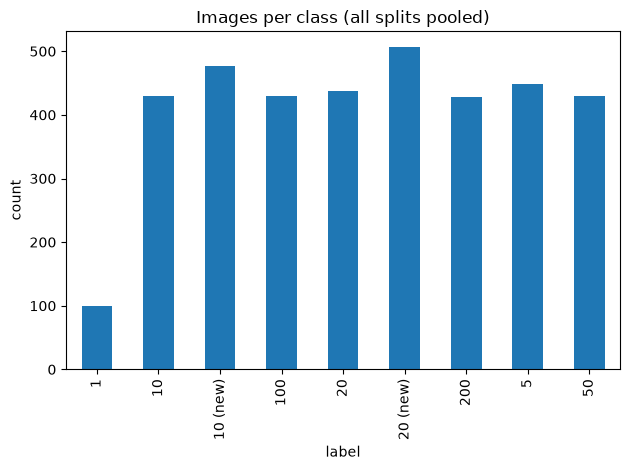

['IMG-20231217-WA0403.jpg', 'IMG_20231217_042224.jpg', 'photo_84_2023-12-16_04-05-38.jpg', 'IMG-20231217-WA0665.jpg', 'IMG_20231217_034817.jpg', 'photo_4_2023-12-16_04-05-38.jpg', 'IMG-20231217-WA0195.jpg', '34 - Copy.jpg']


In [2]:
files = [f for f in DATA_DIR.rglob("*") if f.is_file() and f.suffix.lower() in EXTS]
inv = pd.DataFrame({
    "path": files,
    "label": [f.parent.name for f in files],         
    "orig_split": [f.parent.parent.name for f in files],
})
table = inv.pivot_table(index="label", columns="orig_split", values="path",
                        aggfunc="count", fill_value=0, margins=True)
print(table)

inv["label"].value_counts().sort_index().plot.bar(title="Images per class (all splits pooled)")
plt.ylabel("count"); plt.tight_layout(); plt.show()

print(inv["path"].map(lambda p: p.name).sample(8, random_state=SEED).tolist())

## Step 2: Quality checks
Corrupt files, duplicates (same bytes), and original sizes.

In [3]:
records = []
for _, r in inv.iterrows():
    f = r["path"]
    try:
        with Image.open(f) as im:
            im.verify()
        with Image.open(f) as im:
            w, h = im.size
            mode = im.mode
        records.append({"path": f, "label": r["label"], "orig_split": r["orig_split"],
                        "w": w, "h": h, "mode": mode,
                        "md5": hashlib.md5(f.read_bytes()).hexdigest()})
    except Exception as e:
        print("CORRUPT:", f, e)

df = pd.DataFrame(records)
print("valid images:", len(df))
print("exact duplicates:", df.duplicated("md5").sum())
print("modes:", df["mode"].value_counts().to_dict())
print(df[["w", "h"]].describe().loc[["min", "max", "mean"]])

valid images: 3687
exact duplicates: 452
modes: {'RGB': 3684, 'RGBA': 3}
                w            h
min    189.000000    86.000000
max   4160.000000  6000.000000
mean   908.759696   830.368321


In [4]:
df = df.drop_duplicates("md5").reset_index(drop=True)   
print(df["label"].value_counts())

label
20 (new)    410
10 (new)    404
100         396
5           393
50          392
10          389
20          385
200         380
1            86
Name: count, dtype: int64


## Step 3: Select classes (3 to 5, >=100 images each, roughly balanced)
Fill SELECTED after looking at the table above, and write the reason in the report.

In [5]:
SELECTED = ["5", "10", "20", "50", "100"]
assert 3 <= len(SELECTED) <= 5, "choose 3 to 5 classes"
df = df[df["label"].isin(SELECTED)].reset_index(drop=True)
assert (df["label"].value_counts() >= 100).all(), "each class needs >= 100 images"
print(df["label"].value_counts())

label
100    396
5      393
50     392
10     389
20     385
Name: count, dtype: int64


## Step 4: Stratified split 70/15/15
We split the **file paths first**, before any feature extraction, so nothing leaks from val/test.

In [6]:
train_df, temp_df = train_test_split(
    df, test_size=0.30, stratify=df["label"], random_state=SEED)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED)

for name, part in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(name, len(part), part["label"].value_counts(normalize=True).round(3).to_dict())


out = pd.concat([train_df.assign(split="train"), val_df.assign(split="val"), test_df.assign(split="test")])
out[["path", "label", "split"]].to_csv("splits_part_b.csv", index=False)

train 1368 {'100': 0.202, '5': 0.201, '50': 0.2, '10': 0.199, '20': 0.197}
val 293 {'50': 0.201, '5': 0.201, '100': 0.201, '10': 0.198, '20': 0.198}
test 294 {'100': 0.204, '10': 0.201, '5': 0.201, '50': 0.201, '20': 0.194}


## Step 5: Resize + normalize
Resize to one fixed size, scale pixels to [0, 1]. No statistics are learned here, so there is no leakage.

In [7]:
def load_images(frame):
    X = np.stack([
        np.asarray(Image.open(p).convert("RGB").resize(IMG_SIZE), dtype=np.float32) / 255.0
        for p in frame["path"]
    ])
    return X, frame["label"].to_numpy()

X_train_img, y_train = load_images(train_df)
X_val_img,   y_val   = load_images(val_df)
X_test_img,  y_test  = load_images(test_df)
print(X_train_img.shape, X_val_img.shape, X_test_img.shape)

(1368, 64, 64, 3) (293, 64, 64, 3) (294, 64, 64, 3)


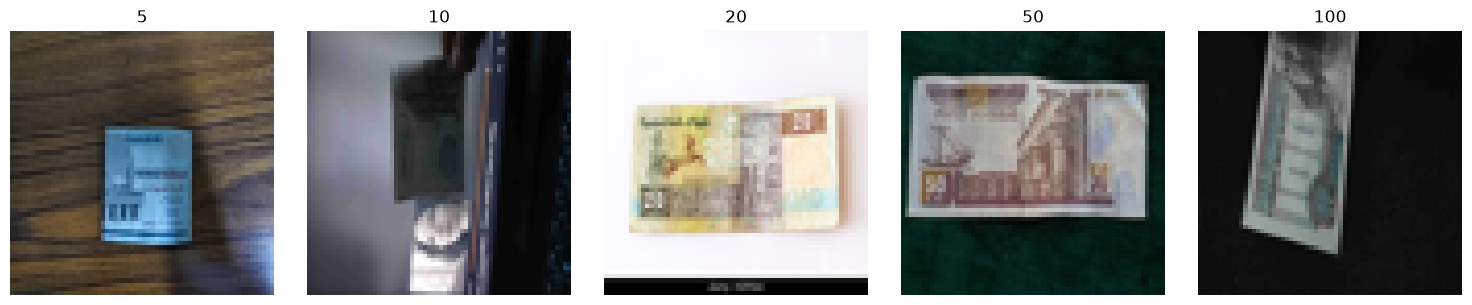

In [8]:
fig, axes = plt.subplots(1, len(SELECTED), figsize=(3 * len(SELECTED), 3))
for ax, cls in zip(np.atleast_1d(axes), SELECTED):
    idx = np.where(y_train == cls)[0][0]
    ax.imshow(X_train_img[idx]); ax.set_title(cls); ax.axis("off")
plt.tight_layout(); plt.show()